In [1]:
# ═══════════════════════════════════════════════════════════════════════
# RESTRICTED 3-VARIABLE VAR — Robustness Check
# ───────────────────────────────────────────────────────────────────────
# Strips the system to its core: [dlog_vix, ASVI8, mag7_ret]
# Removes flow_spy and dy10, both of which were insignificant in every
# specification. If ASVI8 → mag7_ret survives in this minimal system,
# the finding is not an artefact of including irrelevant controls.
# Cholesky ordering: macro risk → attention → price outcome
# ═══════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.vector_ar.var_model import VAR

# ── DATA LOAD (only the 3 series needed) ──────────────────────────────
vix   = pd.read_csv("vix_clean.csv",              parse_dates=["date"])
asvi8 = pd.read_csv("AIStocks_ASVI8_Monthly.csv", parse_dates=["date"])
mag7  = pd.read_csv("mag7_clean.csv",             parse_dates=["date"])

df = (vix
      .merge(asvi8, on="date", how="inner")
      .merge(mag7,  on="date", how="inner")
)
df = df.sort_values("date").reset_index(drop=True)

# ── RESTRICTED VARIABLE SET ───────────────────────────────────────────
restricted_vars = ["dlog_vix", "ASVI8", "mag7_ret"]
var_df = df[restricted_vars + ["date"]].dropna().copy()

print(f"Full sample : {len(var_df)} obs  "
      f"({var_df['date'].min().date()} → {var_df['date'].max().date()})")

# ── STATIONARITY (confirmation — same series as V3, already passed) ───
print("\n" + "═" * 68)
print("ADF TEST  (want p < 0.05 → stationary)")
print("═" * 68)
for name in restricted_vars:
    r = adfuller(df[name].dropna(), autolag="AIC")
    status = "✅" if r[1] < 0.05 else "❌ NON-STATIONARY"
    print(f"{name:<12} | stat: {r[0]:8.3f} | p: {r[1]:.4f} | lags: {r[2]} | {status}")

print()
print("═" * 68)
print("KPSS TEST  (want p > 0.05 → stationary)")
print("═" * 68)
for name in restricted_vars:
    r = kpss(df[name].dropna(), regression="c", nlags="auto")
    status = "✅" if r[1] > 0.05 else "⚠️  CHECK"
    print(f"{name:<12} | stat: {r[0]:8.3f} | p: {r[1]:.4f} | {status}")

Full sample : 121 obs  (2015-12-31 → 2025-12-31)

════════════════════════════════════════════════════════════════════
ADF TEST  (want p < 0.05 → stationary)
════════════════════════════════════════════════════════════════════
dlog_vix     | stat:  -14.697 | p: 0.0000 | lags: 0 | ✅
ASVI8        | stat:   -5.023 | p: 0.0000 | lags: 2 | ✅
mag7_ret     | stat:  -11.013 | p: 0.0000 | lags: 0 | ✅

════════════════════════════════════════════════════════════════════
KPSS TEST  (want p > 0.05 → stationary)
════════════════════════════════════════════════════════════════════
dlog_vix     | stat:    0.049 | p: 0.1000 | ✅
ASVI8        | stat:    0.199 | p: 0.1000 | ✅
mag7_ret     | stat:    0.055 | p: 0.1000 | ✅


/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30569/3736643283.py:52: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30569/3736643283.py:52: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30569/3736643283.py:52: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")


In [2]:
# ═══════════════════════════════════════════════════════════════════════
# HELPER — run_var_restricted()
# ═══════════════════════════════════════════════════════════════════════
# Same pipeline as V3's run_var() but for the 3-variable system.
# Fewer Granger tests (no flow or yield equations to test).
# FEVD and IRF grids are 3×3 instead of 5×5.

def run_var_restricted(var_name, data=None):

    if data is None:
        data = var_df

    cols = ["dlog_vix", "ASVI8", "mag7_ret"]
    idx  = {c: i for i, c in enumerate(cols)}
    sub  = data[cols].copy()

    print("\n" + "═" * 68)
    print(f"  {var_name}  |  N={len(sub)}  |  Variables: {cols}")
    print("═" * 68)

    # ── LAG SELECTION ─────────────────────────────────────────────────
    model   = VAR(sub)
    lag_sel = model.select_order(maxlags=4)
    print("\nLAG SELECTION:")
    print(lag_sel.summary())

    bic_lag  = lag_sel.bic
    aic_lag  = lag_sel.aic
    selected = max(bic_lag, 1)
    print(f"BIC → {bic_lag}  |  AIC → {aic_lag}  |  Using: {selected}")

    # ── ESTIMATION ────────────────────────────────────────────────────
    results = model.fit(maxlags=selected, ic="bic")
    print("\nVAR SUMMARY:")
    print(results.summary())

    # ── STABILITY ─────────────────────────────────────────────────────
    print(f"\nStability check : {results.is_stable()}")
    print(f"Largest eigenvalue modulus : {1 / np.abs(results.roots).min():.4f}")

    # ── GRANGER CAUSALITY ─────────────────────────────────────────────
    print("\nGRANGER CAUSALITY:")
    print(f"{'Test':<35} | {'F-stat':>8} | {'p-value':>8} | Result")
    print("─" * 70)

    gc_tests = [
        ("ASVI8",    "mag7_ret", "ASVI8 → mag7_ret"),
        ("mag7_ret", "ASVI8",    "mag7_ret → ASVI8"),
        ("dlog_vix", "mag7_ret", "VIX → mag7_ret"),
        ("dlog_vix", "ASVI8",    "VIX → ASVI8"),
        ("ASVI8",    "dlog_vix", "ASVI8 → VIX"),
    ]
    for cause, effect, label in gc_tests:
        r   = results.test_causality(effect, [cause], kind="f")
        sig = "✅ p<0.05" if r.pvalue < 0.05 else ("⚠️  p<0.10" if r.pvalue < 0.10 else "—")
        print(f"{label:<35} | {r.test_statistic:>8.3f} | {r.pvalue:>8.4f} | {sig}")

    # ── RESIDUAL DIAGNOSTICS ──────────────────────────────────────────
    print("\nWHITENESS TEST (Portmanteau, nlags=10):")
    print(results.test_whiteness(nlags=10).summary())

    print("\nNORMALITY TEST:")
    print(results.test_normality().summary())

    # ── RESIDUAL CORRELATION MATRIX ───────────────────────────────────
    resid_corr = pd.DataFrame(
        np.corrcoef(results.resid.T),
        columns=cols, index=cols
    )
    print("\nRESIDUAL CORRELATION MATRIX:")
    print(resid_corr.round(4))

    # ── IRFs ──────────────────────────────────────────────────────────
    irf = results.irf(12)

    # Full 3×3 grid
    irf.plot(orth=True, figsize=(10, 8))
    plt.suptitle(f"Orthogonalised IRFs — {var_name}", y=1.01, fontsize=13)
    plt.tight_layout()
    plt.show()

    # Focused: the two key relationships
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    focused = [
        ("ASVI8",    "mag7_ret", "ASVI8 shock → Mag7 returns"),
        ("mag7_ret", "ASVI8",    "Mag7 shock → ASVI8"),
    ]
    for ax, (imp, resp, title) in zip(axes, focused):
        irf_vals = irf.orth_irfs[:, idx[resp], idx[imp]]
        stderr   = irf.stderr(orth=True)[:, idx[resp], idx[imp]]
        ci_lo    = irf_vals - 1.96 * stderr
        ci_hi    = irf_vals + 1.96 * stderr
        horizons = np.arange(len(irf_vals))

        ax.plot(horizons, irf_vals, color="navy", linewidth=2, label="IRF")
        ax.fill_between(horizons, ci_lo, ci_hi, alpha=0.2, color="steelblue", label="95% CI")
        ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Months after shock")
        ax.legend(fontsize=8)

    plt.suptitle(f"Key IRFs — {var_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # ── FEVD ──────────────────────────────────────────────────────────
    fevd = results.fevd(12)

    fevd.plot(figsize=(10, 6))
    plt.suptitle(f"FEVD — {var_name}", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()

    print(f"\nFEVD — share of mag7_ret forecast error variance:")
    print(f"{'Variable':<12} | {'t=1':>8} | {'t=6':>8} | {'t=12':>8}")
    print("─" * 45)
    fevd_df = pd.DataFrame(
        fevd.decomp[idx["mag7_ret"]],
        columns=cols
    )
    for var in cols:
        print(f"{var:<12} | {fevd_df[var].iloc[0]:>7.1%} | {fevd_df[var].iloc[5]:>7.1%} | {fevd_df[var].iloc[11]:>7.1%}")

    return results


════════════════════════════════════════════════════════════════════
  Restricted VAR — Full Sample  |  N=121  |  Variables: ['dlog_vix', 'ASVI8', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -9.601      -9.530   6.767e-05      -9.572
1      -10.64     -10.35*   2.404e-05      -10.52
2     -10.74*      -10.25  2.165e-05*     -10.54*
3      -10.67      -9.964   2.321e-05      -10.38
4      -10.68      -9.757   2.313e-05      -10.30
-------------------------------------------------
BIC → 1  |  AIC → 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:46:46
--------------------------------------------------------------------
No. of Equatio

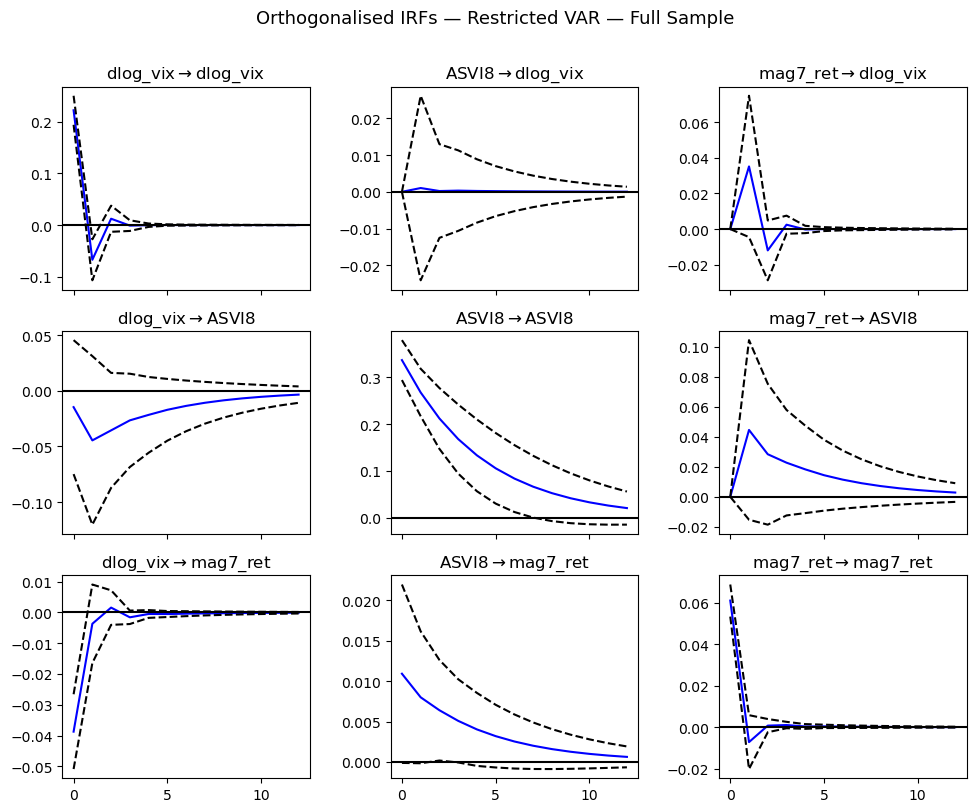

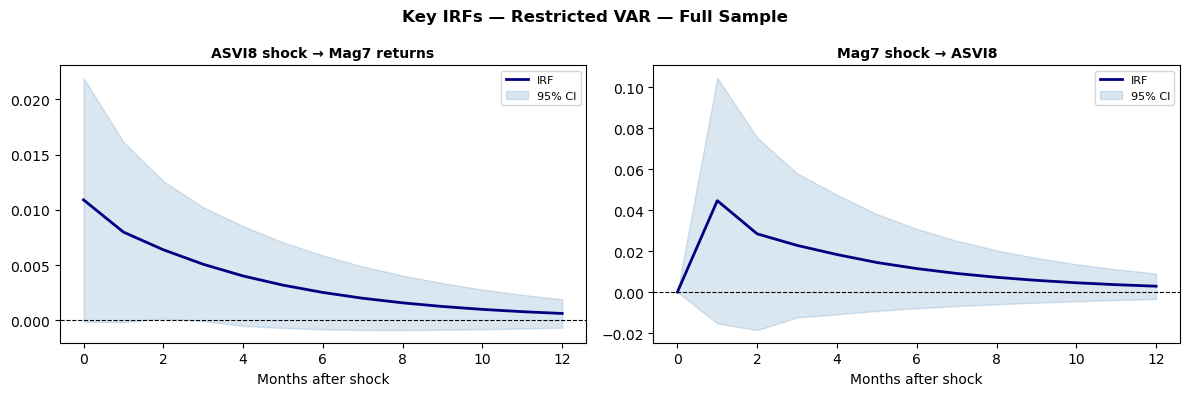

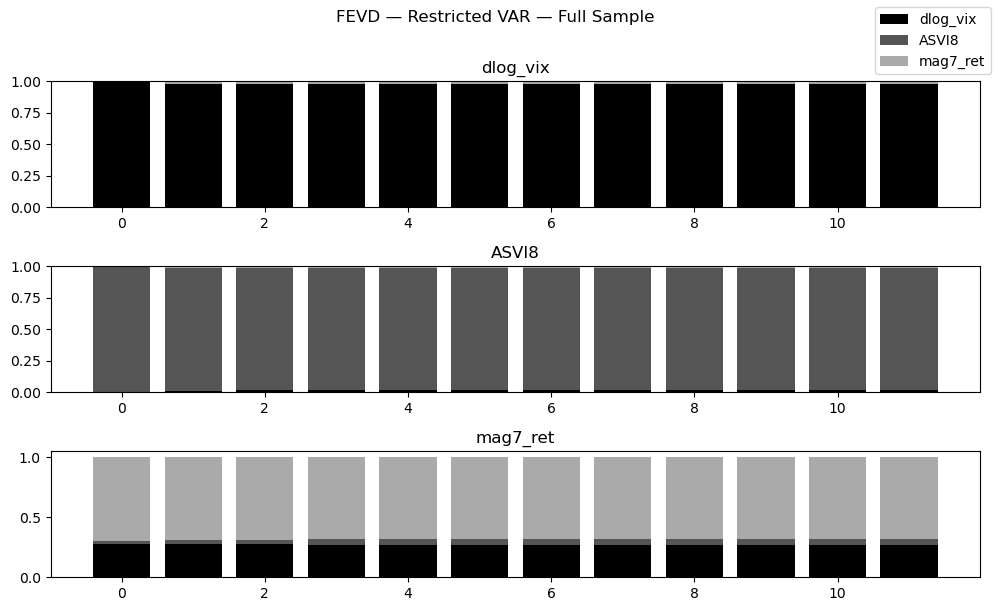


FEVD — share of mag7_ret forecast error variance:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   28.0% |   27.2% |   27.1%
ASVI8        |    2.2% |    4.9% |    5.2%
mag7_ret     |   69.8% |   67.9% |   67.7%


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# RUN — FULL SAMPLE (Dec 2015 – Dec 2025)
# ═══════════════════════════════════════════════════════════════════════

results_full = run_var_restricted("Restricted VAR — Full Sample")

2021+ subsample: 61 obs

════════════════════════════════════════════════════════════════════
  Restricted VAR — 2021+  |  N=61  |  Variables: ['dlog_vix', 'ASVI8', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -9.173      -9.065   0.0001038      -9.131
1      -10.57     -10.14*  2.580e-05*     -10.40*
2      -10.51      -9.753   2.748e-05      -10.21
3      -10.46      -9.382   2.907e-05      -10.04
4     -10.58*      -9.184   2.600e-05      -10.04
-------------------------------------------------
BIC → 1  |  AIC → 4  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:46:47
------------------------------------------------------------------

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


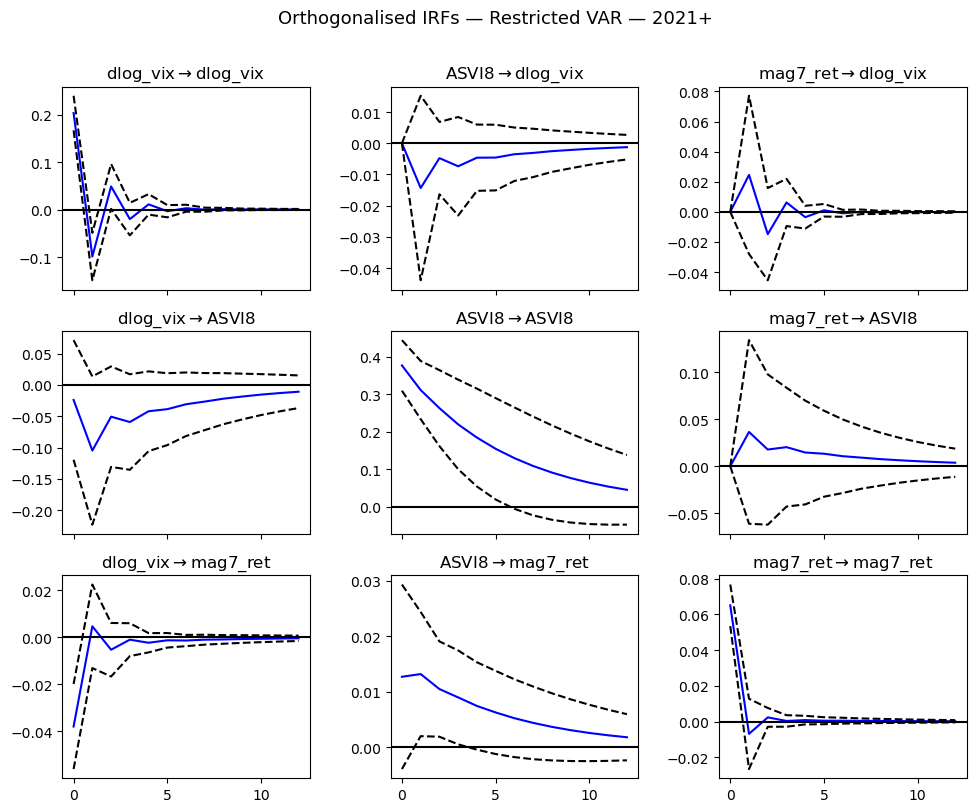

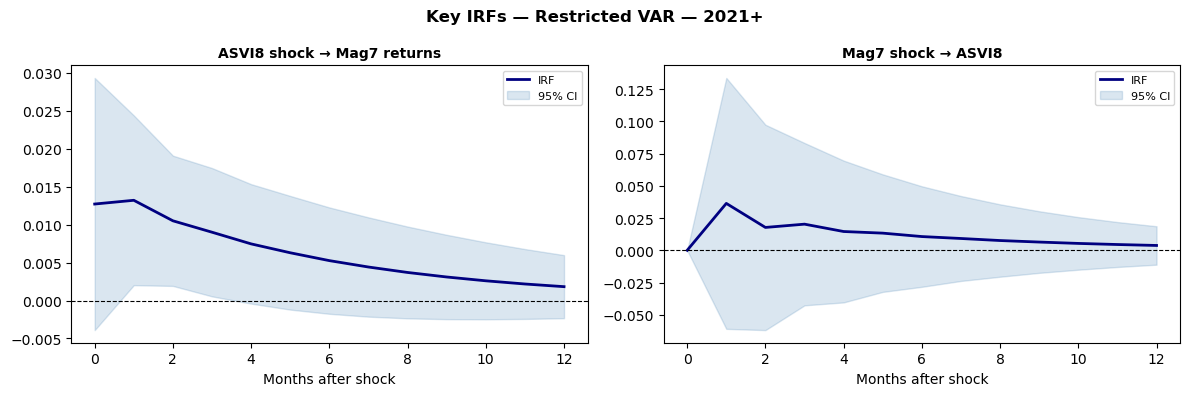

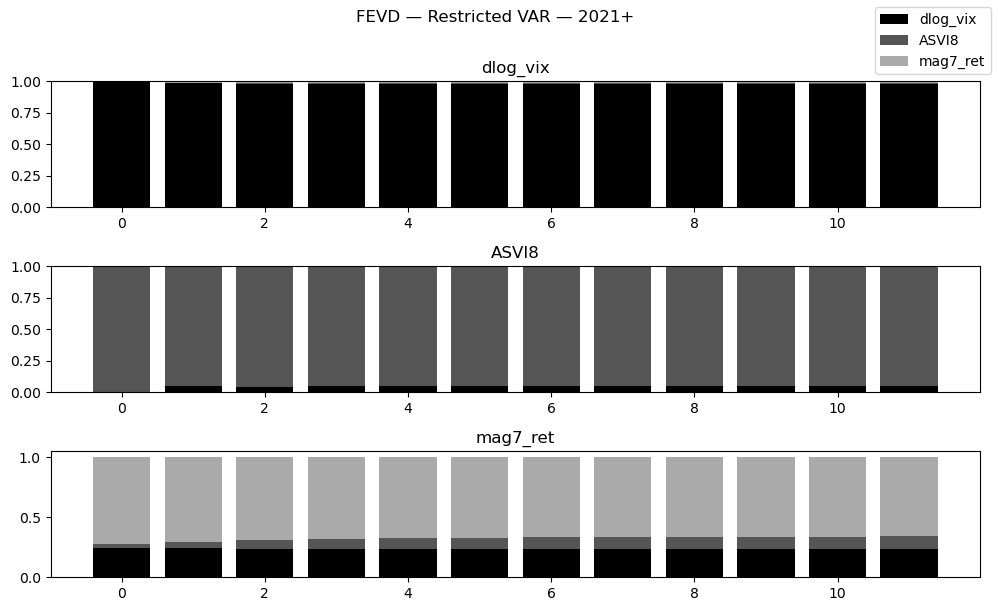


FEVD — share of mag7_ret forecast error variance:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   24.7% |   23.4% |   23.2%
ASVI8        |    2.8% |    9.7% |   10.8%
mag7_ret     |   72.5% |   66.9% |   66.0%


In [4]:
# ═══════════════════════════════════════════════════════════════════════
# RUN — 2021+ SUBSAMPLE
# ═══════════════════════════════════════════════════════════════════════

var_df_2021 = var_df[var_df["date"] >= "2020-12-31"].copy()
print(f"2021+ subsample: {len(var_df_2021)} obs")

results_2021 = run_var_restricted("Restricted VAR — 2021+", data=var_df_2021)